#OZUP Projekt - Kreditna (ne)sposobnost

Izradili: Luka Gvozdanović i Dominik Katunić

##Razumijevanje domene

###Poslovni ciljevi:

Naš primarni poslovni cilj ovog projekta je predvidjeti kreditnu sposobnost klijenata. Želimo procijeniti rizik da li klijent ne može ili može vratiti odobreni kredit.

Ovim rješenjem mogli bi se smanjiti gubitci uzrokovani nenaplativim kreditima, povećati profitabilnost kreditnig portfelja, poboljšati kvalitetu usluge nudeći prilagođene uvjete otplaćivanja kredita klijentima s dobrim profilom, te brže i točnije donosti odluke o odobravanju ili odbijanju kredita.

Osim predviđanja kreditne sposobnosti klijenta zanumaju nas koje karakteristike najviše utječu na kreditni rizik, kako možemo podijeliti klijente u grupe s različitim razinama rizika, koje vrste klijenata su najbolji kandidati za veće kredite ili dodatne financijske usluge te mogu li se rizični klijenti ranije identificirati kako bi im se ponudili alternativni financijski proizvodi ili slično.


###Ciljevi rudarenja podataka:

Glavni cilj rudarenja podataka nam je razviti prediktivni model koji klasificira klijente u dvije kategoreije: niski rizik (kreditno nesposoban) i visoki rizik (kreditno sposoban). Osim toga bitno nam je analizirati važnost pojedinih atributa za bolje razumijevanje faktora rizika.

###Znanstveni radovi

Nakon pretraživanja različitih znanstvenih radova, pronašli smo ova tri znanstvena rada i njih smo izdvojili jer imaju najsličniji skup podataka naše skupu podataka:

1) Credit scoring and default risk prediction:

Ovaj znanstveni rad ima 195 kreditnih podataka, te je korišten algoritam logističke regresije. Nakon cijelog procesa rudarenja podataka, i treniranja i testiranja modela, dobivena je točnost modela od 76.7% i 76.4%.

2) Research on Credit Risk Evaluation of Commercial Banks

Ovaj znanstveni rad koristi stvarne podatke s Lending Club platforme i to je veliki skup podataka, te se iz tog razloga koristio algoritam neuronske mreže. Nakon cijelog procesa, set za trening je imao točnost od 91%, a set za testiranje je imao točnost od 97% što je puno bolje nego prvi model.

3) A study on predicting loan

Ovaj znanstveni rad koristi podatke vrlo sličnim našima, te je korišten random forest algoritam. Na kraju modeliranja, točnost ovog modela je 98% što je vrlo dobro kao i rezultat drugog znanstvenog rada.

Za naše potrebe, zaključili smo da je najbolje koristiti random forest algoritam jer ima najbolje rezultate testiranja i jer je odličan za manje skupove podataka kao što je to naš. Prvi algoritam, odnosno logistička regresija je imala najmanju točnost od ova tri algoritma. Nadalje nismo htjeli uzeti algoritam neuronskih mreža jer naš skup podataka nije toliko velik i korištenje neuronskih mreža moglo bi usporiti proces.


##Razumijevanje podataka

### Značajke credit_data  
• **Age**: Starost  
• **Sex**: Spol  
• **Job**: broj poslova  
• **Housing**: Ima svoju nekretninu  
• **Saving accounts**: Visina štednje (kategorična)  
• **Checking account**: Visina iznosa na tekućem računu (kategorična)  
• **Credit amount**: Visina iznosa kredita  
• **Duration**: Rok otplate  
• **Purpose**: Za što se podiže kredit  
• **Risk**: Značajka koju predviđamo - rizični korisnik  

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import random

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, explained_variance_score

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error, explained_variance_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from multiprocessing import get_context, Pool

####Uvoz podataka i njihova provjera kvalitete

In [ ]:
df_row = pd.read_csv('sample_data/Tim_02_credit_data.csv')
df_row.head(10)

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad
5,5,35,male,1,free,NaN,NaN,9055,36,education,good
6,6,53,male,2,own,quite rich,NaN,2835,24,furniture/equipment,good
7,7,35,male,3,rent,little,moderate,6948,36,car,good
8,8,61,male,1,own,rich,NaN,3059,12,radio/TV,good
9,9,28,male,3,own,little,moderate,5234,30,car,bad


In [ ]:
df_row.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
 10  Risk              1000 non-null   object
dtypes: int64(5), object(6)
memory usage: 86.1+ KB


In [ ]:
df_row.shape

(1000, 11)

####Suma null vrijednosti

In [ ]:
df_row.isnull().sum()

,0
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,183
Checking account,394
Credit amount,0
Duration,0
Purpose,0


In [ ]:
missing_percentage = (df_row.isnull().sum() / len(df_row)) * 100
print(missing_percentage[missing_percentage > 0])

Saving accounts     18.3
Checking account    39.4
dtype: float64


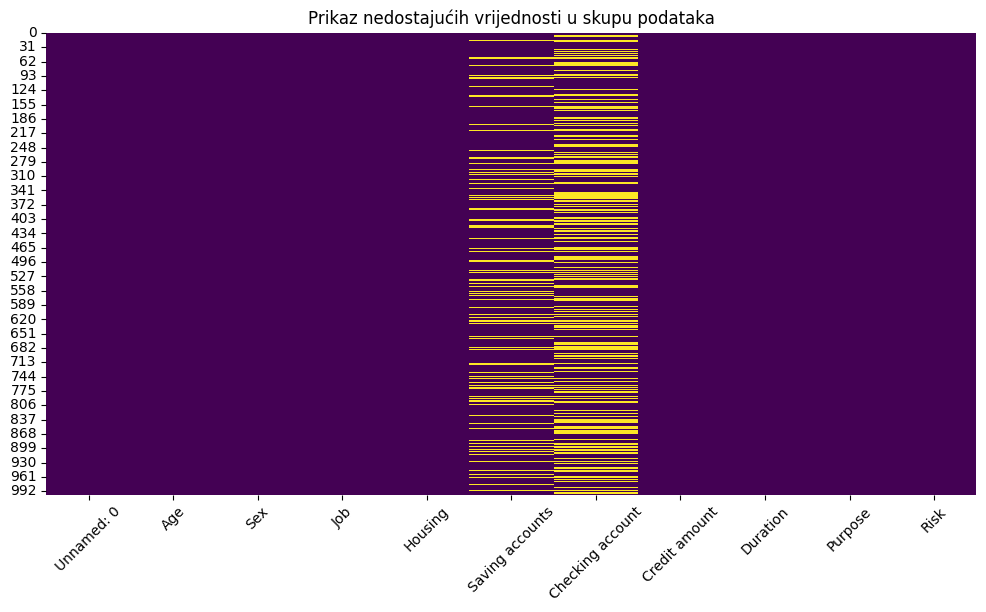

In [ ]:
plt.figure(figsize=(12, 6))
sns.heatmap(df_row.isnull(), cbar=False, cmap='viridis')
plt.title('Prikaz nedostajućih vrijednosti u skupu podataka')
plt.xticks(rotation=45)
plt.show()

####Ispis jedinstvenih vrijednosti kategorijskih atributa

In [ ]:
stupci = ['Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose', 'Risk']

for col in stupci:
    print('Unique',f'{col}: {df_row[col].unique()}\n')

print('Zbroj "good" rizika: ', df_row[df_row['Risk'] == 'good'].shape[0])
print('Zbroj "bad" rizika: ', df_row[df_row['Risk'] == 'bad'].shape[0])

Unique Job: [2 1 3 0]

Unique Housing: ['own' 'free' 'rent']

Unique Saving accounts: [nan 'little' 'quite rich' 'rich' 'moderate']

Unique Checking account: ['little' 'moderate' nan 'rich']

Unique Purpose: ['radio/TV' 'education' 'furniture/equipment' 'car' 'business'
 'domestic appliances' 'repairs' 'vacation/others']

Unique Risk: ['good' 'bad']

Zbroj "good" rizika:  700
Zbroj "bad" rizika:  300


####Deskriptivna statistika

In [ ]:
num_variables = df_row.drop(['Housing', 'Saving accounts', 'Checking account', 'Purpose', 'Risk'], axis=1)
num_variables.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0,499.500,288.819436,0.0,249.75,499.5,749.25,999.0
Age,1000.0,35.546,11.375469,19.0,27.00,33.0,42.00,75.0
Job,1000.0,1.904,0.653614,0.0,2.00,2.0,2.00,3.0
Credit amount,1000.0,3271.258,2822.736876,250.0,1365.50,2319.5,3972.25,18424.0
Duration,1000.0,20.903,12.058814,4.0,12.00,18.0,24.00,72.0


####Analiza atributa pojedinačno

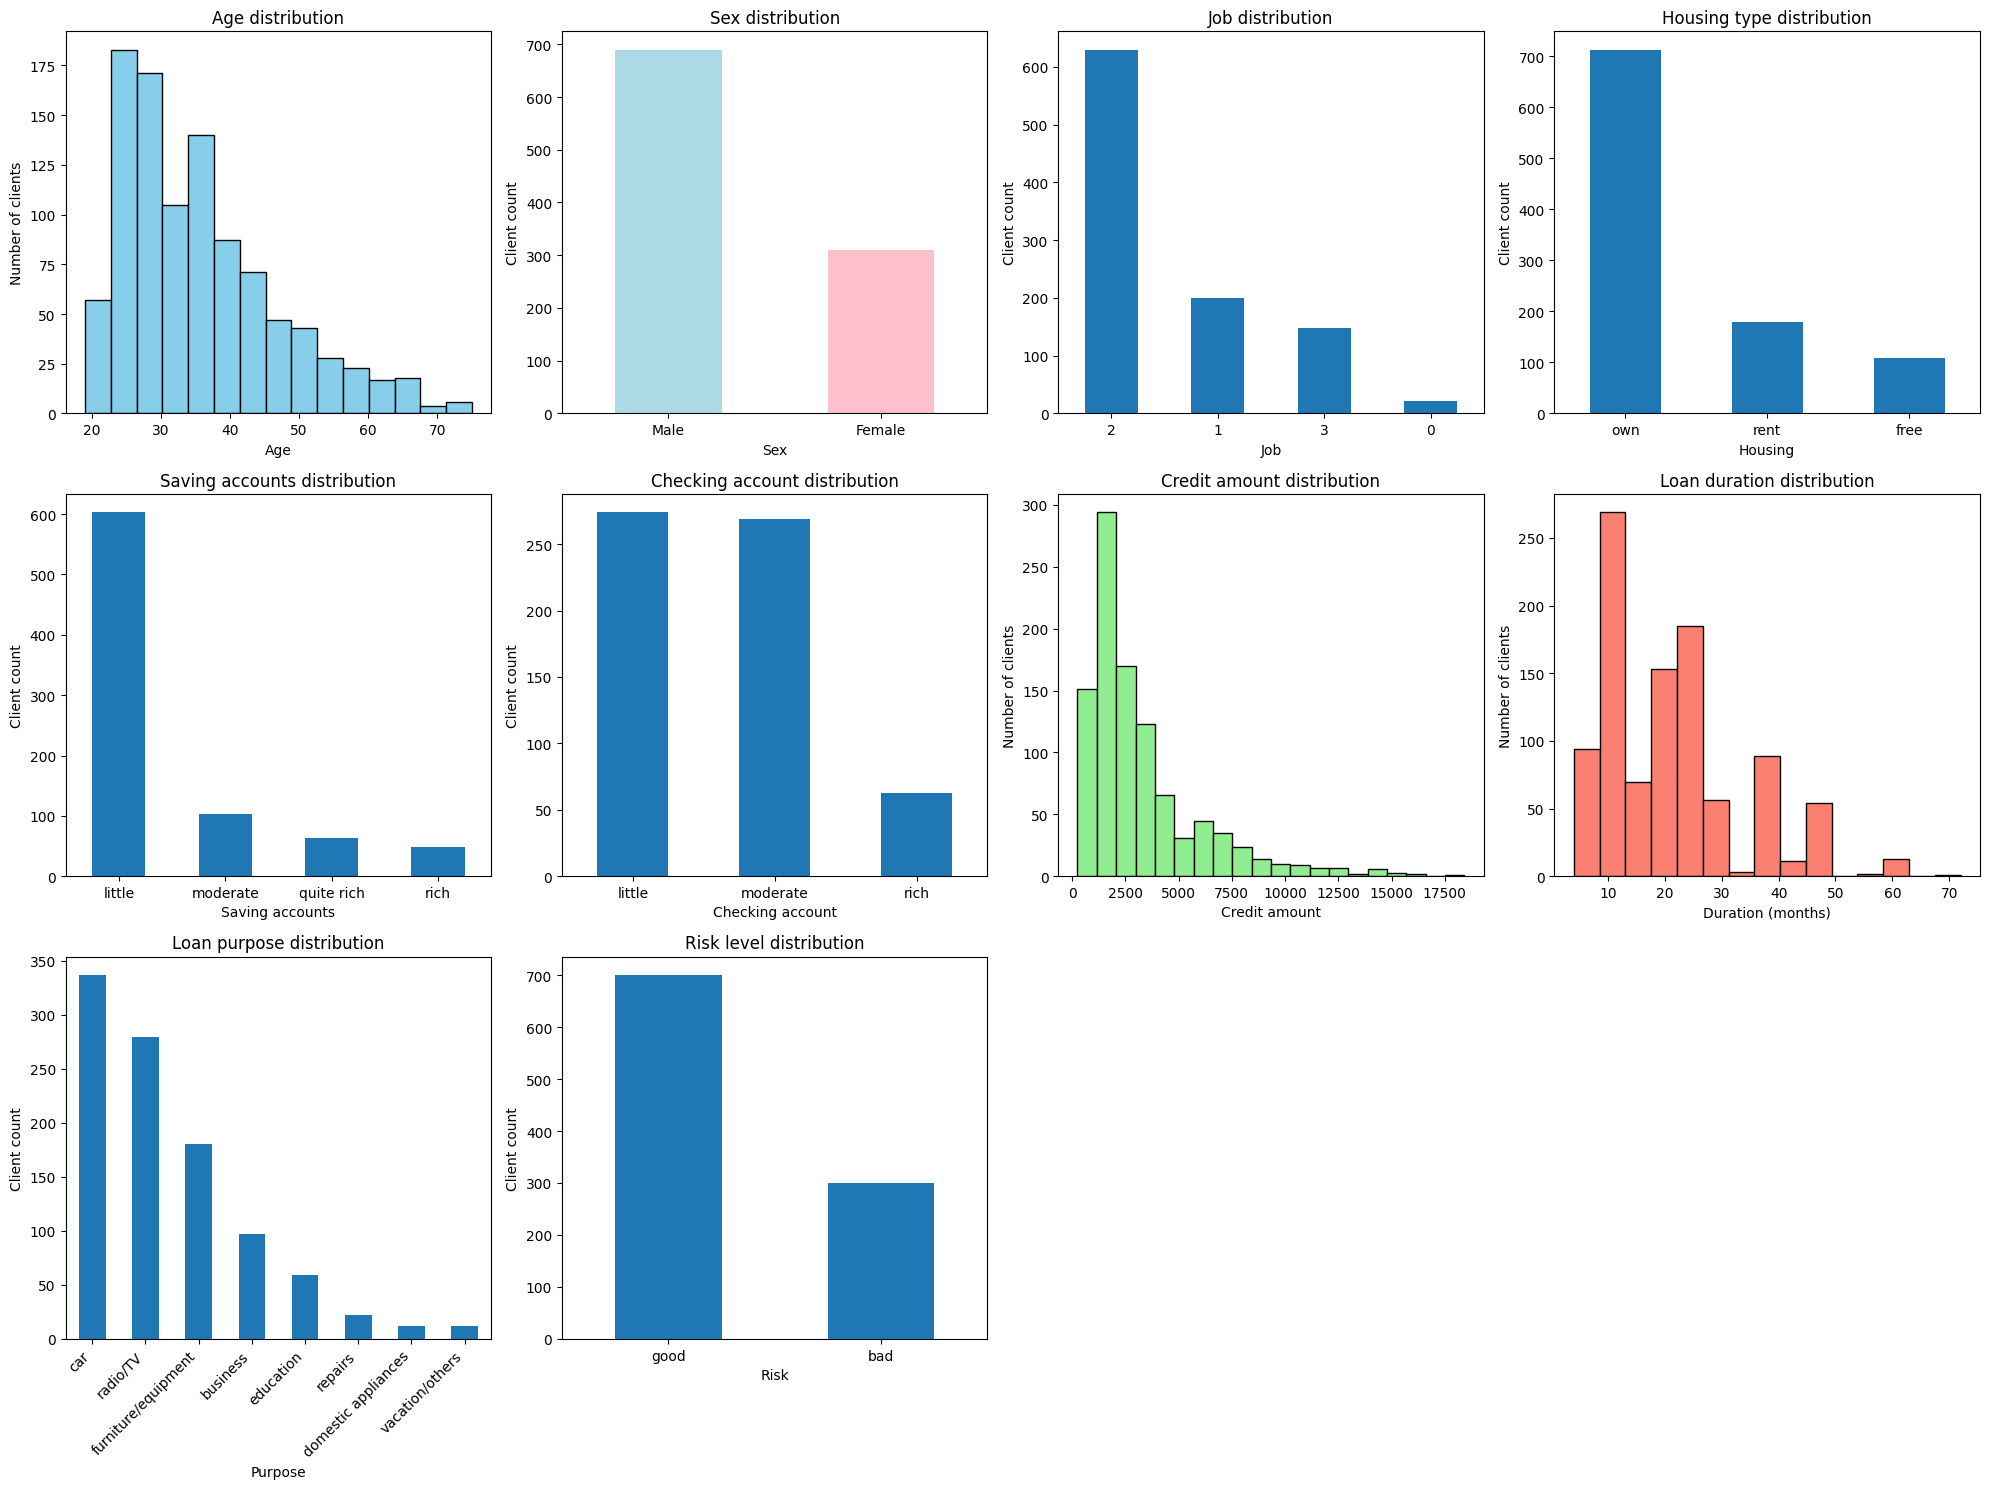

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

# AGE
df_row['Age'].plot(kind='hist', bins=15, color='skyblue', edgecolor='black', ax=axes[0], title='Age distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Number of clients')

# SEX
df_row['Sex'].value_counts().plot(kind='bar', color=['lightblue', 'pink'], ax=axes[1], title='Sex distribution')
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('Client count')
axes[1].set_xticklabels(['Male', 'Female'], rotation=0)

# JOB
df_row['Job'].value_counts().plot(kind='bar', ax=axes[2], title='Job distribution')
axes[2].set_xlabel('Job')
axes[2].set_ylabel('Client count')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)

# HOUSING
df_row['Housing'].value_counts().plot(kind='bar', ax=axes[3], title='Housing type distribution')
axes[3].set_xlabel('Housing')
axes[3].set_ylabel('Client count')
axes[3].set_xticklabels(axes[3].get_xticklabels(), rotation=0)

# SAVING ACCOUNTS
df_row['Saving accounts'].value_counts().plot(kind='bar', ax=axes[4], title='Saving accounts distribution')
axes[4].set_xlabel('Saving accounts')
axes[4].set_ylabel('Client count')
axes[4].set_xticklabels(axes[4].get_xticklabels(), rotation=0)

# CHECKING ACCOUNT
df_row['Checking account'].value_counts().plot(kind='bar', ax=axes[5], title='Checking account distribution')
axes[5].set_xlabel('Checking account')
axes[5].set_ylabel('Client count')
axes[5].set_xticklabels(axes[5].get_xticklabels(), rotation=0)

# CREDIT AMOUNT
df_row['Credit amount'].plot(kind='hist', bins=20, color='lightgreen', edgecolor='black', ax=axes[6], title='Credit amount distribution')
axes[6].set_xlabel('Credit amount')
axes[6].set_ylabel('Number of clients')

# DURATION
df_row['Duration'].plot(kind='hist', bins=15, color='salmon', edgecolor='black', ax=axes[7], title='Loan duration distribution')
axes[7].set_xlabel('Duration (months)')
axes[7].set_ylabel('Number of clients')

# PURPOSE
df_row['Purpose'].value_counts().plot(kind='bar', ax=axes[8], title='Loan purpose distribution')
axes[8].set_xlabel('Purpose')
axes[8].set_ylabel('Client count')
axes[8].set_xticklabels(axes[8].get_xticklabels(), rotation=45, ha='right')

# RISK
df_row['Risk'].value_counts().plot(kind='bar', ax=axes[9], title='Risk level distribution')
axes[9].set_xlabel('Risk')
axes[9].set_ylabel('Client count')
axes[9].set_xticklabels(axes[9].get_xticklabels(), rotation=0)

for i in range(10, 12):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

###Matrice korelacija numeričkih atributa

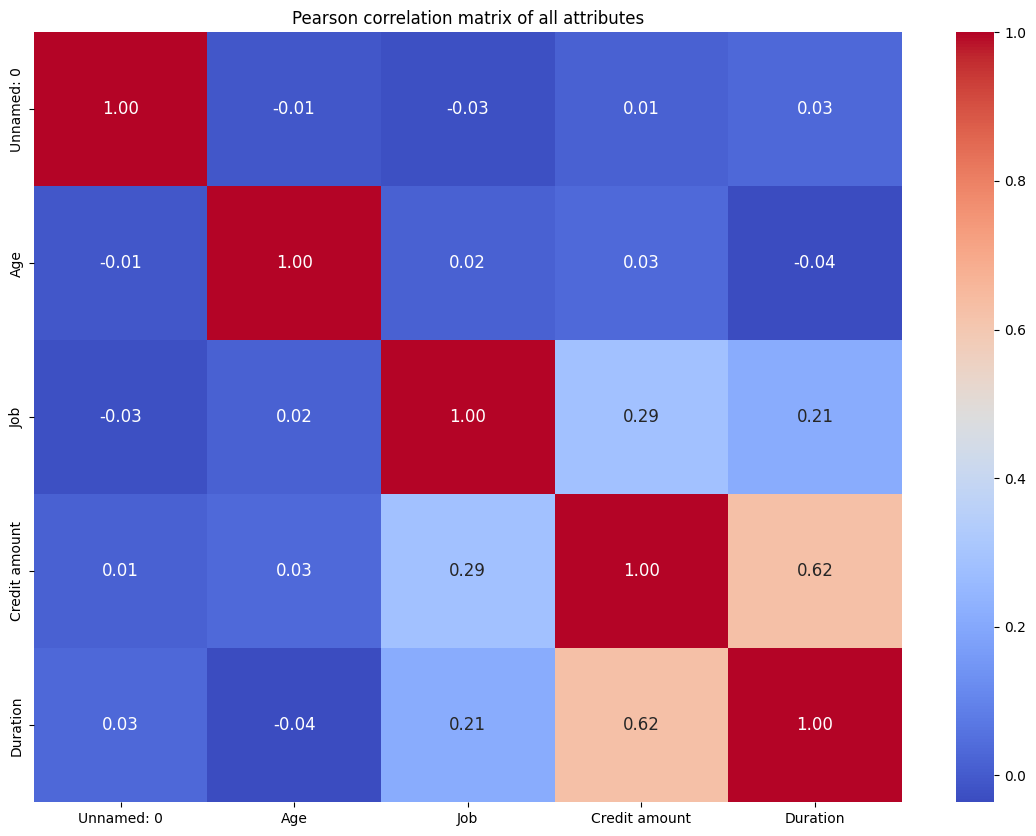

In [ ]:
plt.figure(figsize=(14,10))
sns.heatmap(df_row.corr(numeric_only=True), cmap="coolwarm", annot=True, annot_kws={"size":12}, fmt='.2f')
plt.title('Pearson correlation matrix of all attributes')
plt.show()

###Rizik prema dobnim skupinama

<ipython-input-45-f7990dbcba26>:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  godine = df_row.groupby(['Age group', 'Risk']).size().unstack().div(df_row.groupby('Age group').size(), axis=0) * 100
<ipython-input-45-f7990dbcba26>:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  godine = df_row.groupby(['Age group', 'Risk']).size().unstack().div(df_row.groupby('Age group').size(), axis=0) * 100


(array([0, 1, 2, 3]),
 [Text(0, 0, '18-30'),
  Text(1, 0, '31-45'),
  Text(2, 0, '46-60'),
  Text(3, 0, '60+')])

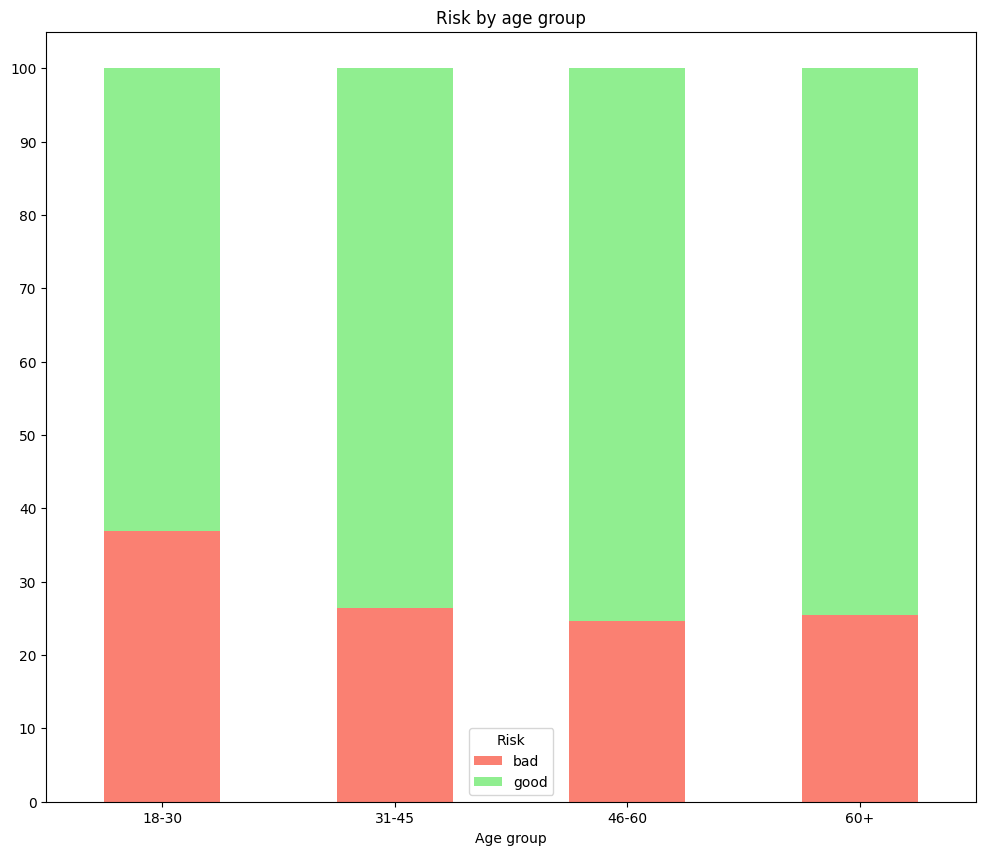

In [ ]:
df_row['Age group'] = pd.cut(df_row['Age'], bins=[18, 30, 45, 60, 100], labels=['18-30', '31-45', '46-60', '60+'], right=False)

godine = df_row.groupby(['Age group', 'Risk']).size().unstack().div(df_row.groupby('Age group').size(), axis=0) * 100
godine.plot(kind='bar', stacked=True, color=['salmon', 'lightgreen'], figsize=(12,10))

plt.title('Risk by age group')
plt.yticks(np.arange(0, 101, step=10))
plt.xticks(rotation=0,)

###Iznos kredita u odnosu na trajanje

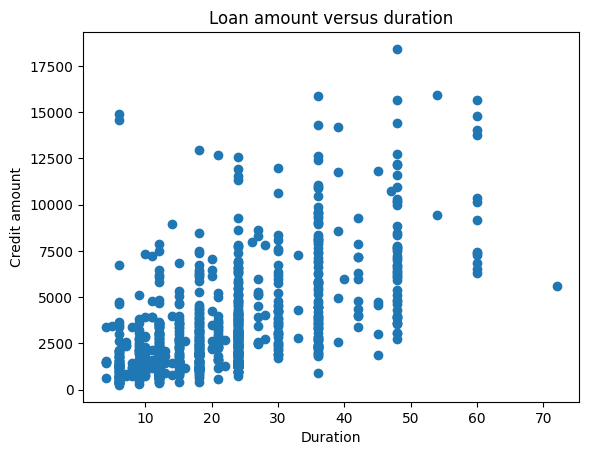

In [ ]:
x = df_row['Duration']
y = df_row['Credit amount']

plt.title("Loan amount versus duration")
plt.xlabel("Duration")
plt.ylabel("Credit amount")
plt.scatter(x, y)
plt.show()

###Iznos kredita prema riziku

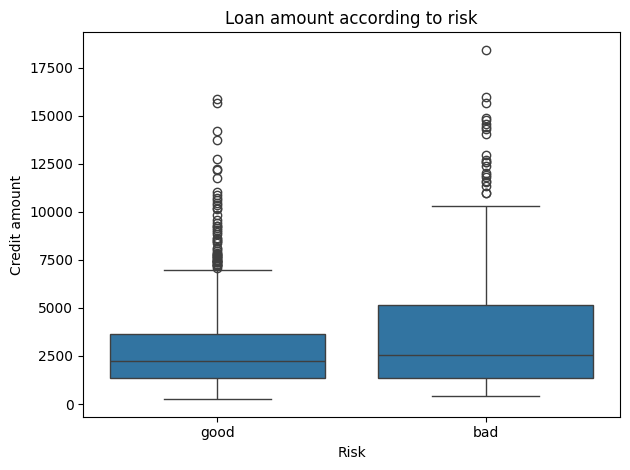

In [ ]:
sns.boxplot(data=df_row, x='Risk', y='Credit amount')
plt.title('Loan amount according to risk')
plt.xlabel('Risk')
plt.ylabel('Credit amount')
plt.tight_layout()

###Najčešći razlozi uzimanja kredita

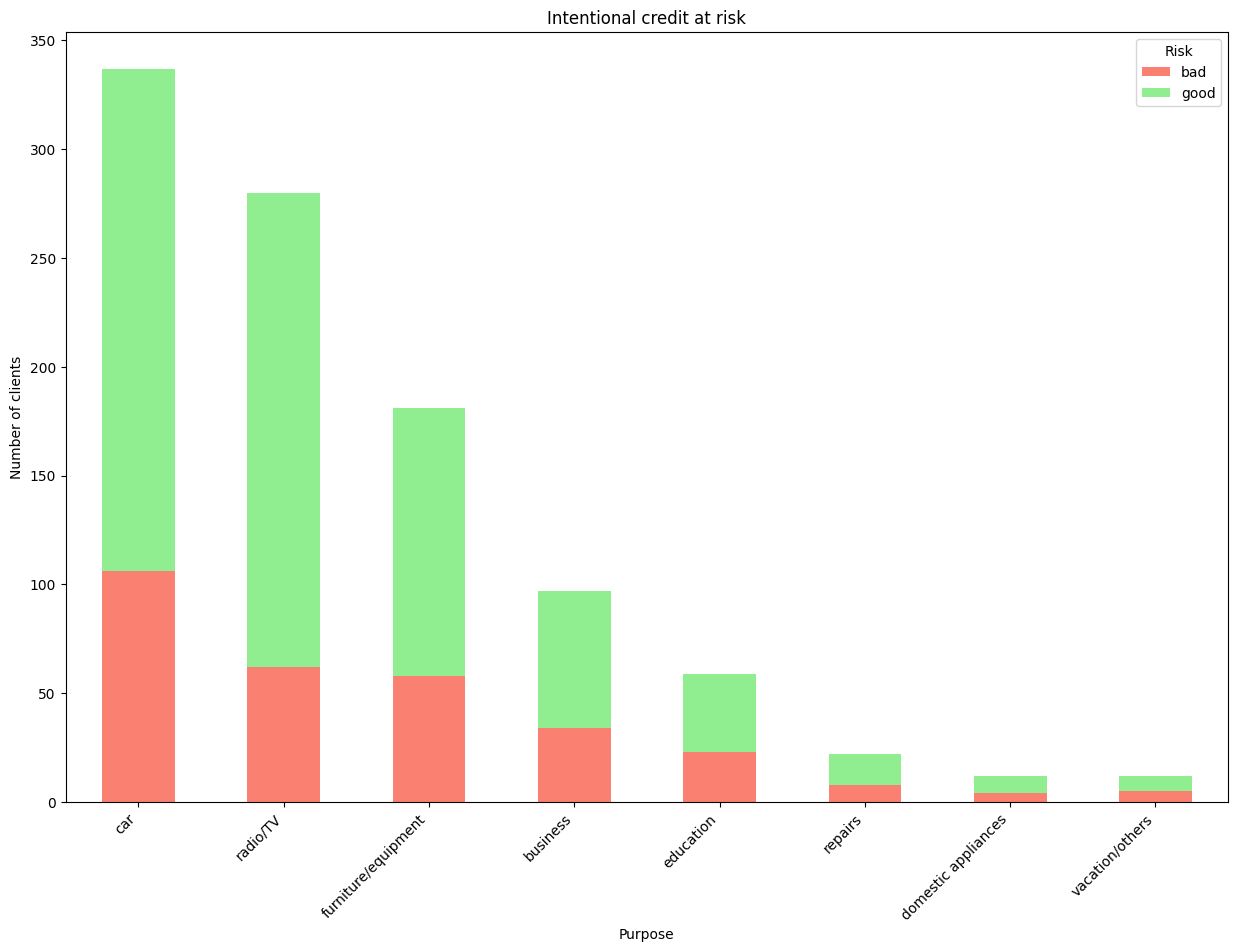

In [ ]:
korist = df_row.groupby(['Purpose', 'Risk']).size().unstack(fill_value=0)
korist = korist.loc[korist.sum(axis=1).sort_values(ascending=False).index]
korist.plot(kind='bar', stacked=True, figsize=(15, 10), color=['salmon', 'lightgreen'])

plt.title('Intentional credit at risk')
plt.xlabel('Purpose')
plt.ylabel('Number of clients')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Risk')

plt.show()

###Raspodjela rizika prema stanju na štednom računu

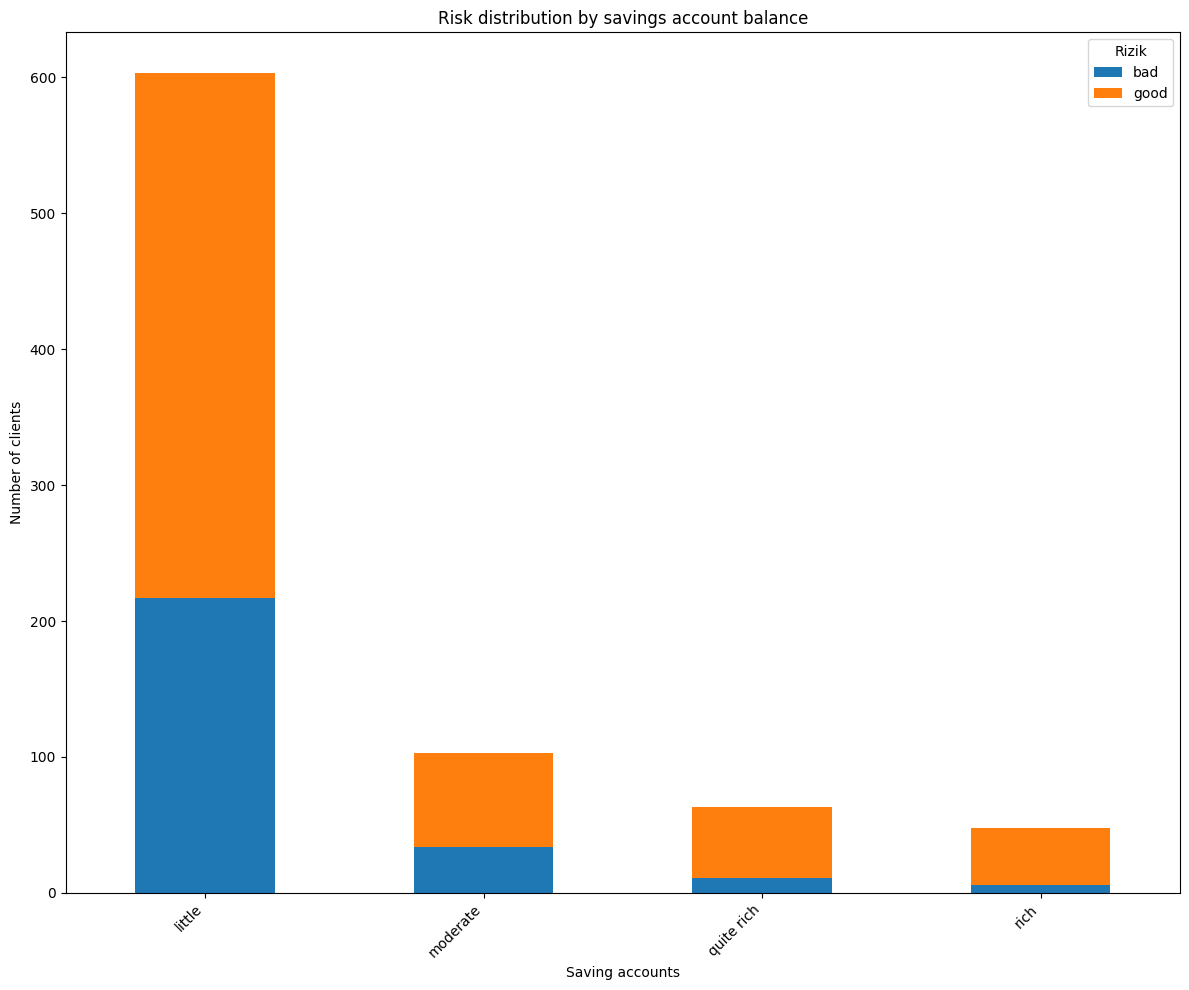

In [ ]:
df_row.groupby(['Saving accounts', 'Risk']).size().unstack().plot(kind='bar', stacked=True, figsize=(12,10))
plt.title('Risk distribution by savings account balance')
plt.xlabel('Saving accounts')
plt.ylabel('Number of clients')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Rizik')
plt.tight_layout()

###Iznos kredita po poslu

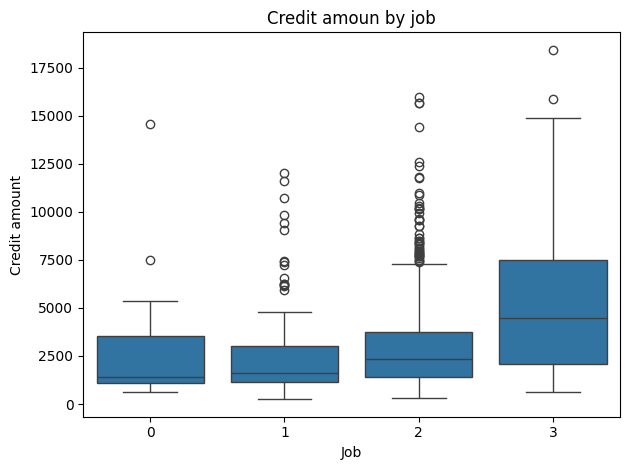

In [ ]:
sns.boxplot(data=df_row, x='Job', y='Credit amount')
plt.title('Credit amoun by job')
plt.xlabel('Job')
plt.ylabel('Credit amount')
plt.tight_layout()

###Trajanje kredita prema poslu

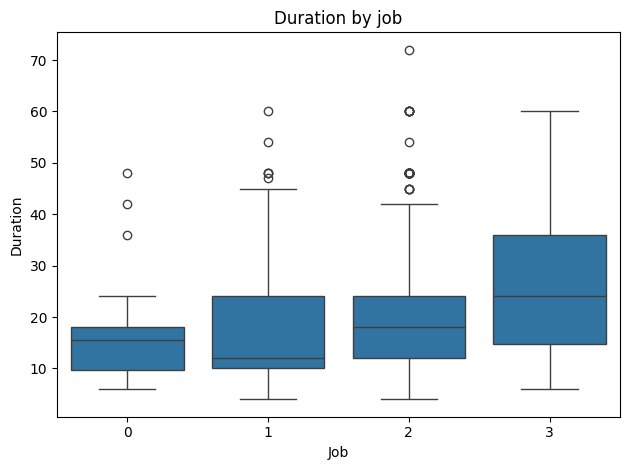

In [ ]:
sns.boxplot(data=df_row, x='Job', y='Duration')
plt.title('Duration by job')
plt.xlabel('Job')
plt.ylabel('Duration')
plt.tight_layout()

###Raspodjela rizika prema vrsti stanovanja

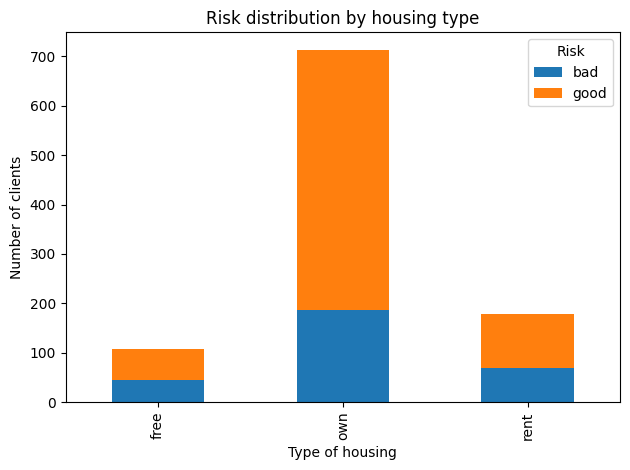

In [ ]:
df_row.groupby(['Housing', 'Risk']).size().unstack().plot(kind='bar', stacked=True)
plt.title('Risk distribution by housing type')
plt.xlabel('Type of housing')
plt.ylabel('Number of clients')
plt.legend(title='Risk')
plt.tight_layout()

###Trajanje kredita uzimajući u obzir rizik

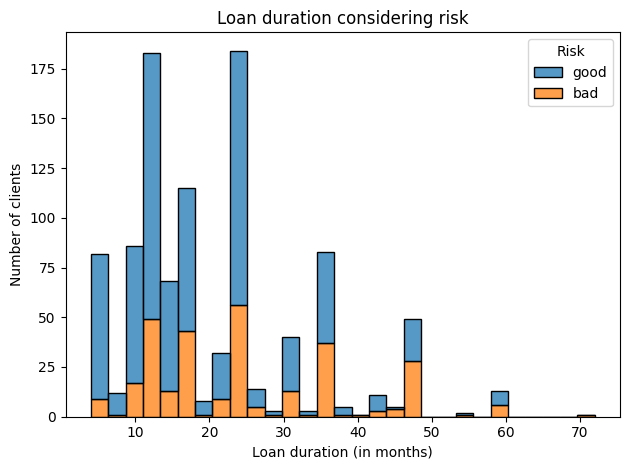

In [ ]:
sns.histplot(data=df_row, x='Duration', hue='Risk', multiple='stack')
plt.title('Loan duration considering risk')
plt.xlabel('Loan duration (in months)')
plt.ylabel('Number of clients')
plt.tight_layout()

#2. Faza projekta

##Priprema podataka

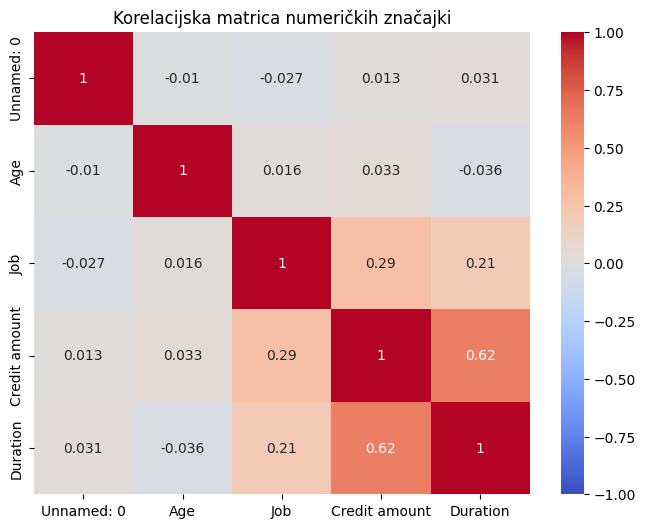

In [ ]:
numeric_df = df_row.select_dtypes(include='number')
corr_matrix = numeric_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Korelacijska matrica numeričkih značajki")
plt.show()

Kao što vidimo sa grafa, nema velike multikolinearnosti. Najveća je 0.62 koja je između Credit amount-a i Duration-a, što nam govori da je tu najveća povezanost.

##Čišćenje podataka

In [ ]:
df_row.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Unnamed: 0        1000 non-null   int64   
 1   Age               1000 non-null   int64   
 2   Sex               1000 non-null   object  
 3   Job               1000 non-null   int64   
 4   Housing           1000 non-null   object  
 5   Saving accounts   817 non-null    object  
 6   Checking account  606 non-null    object  
 7   Credit amount     1000 non-null   int64   
 8   Duration          1000 non-null   int64   
 9   Purpose           1000 non-null   object  
 10  Risk              1000 non-null   object  
 11  Age group         1000 non-null   category
dtypes: category(1), int64(5), object(6)
memory usage: 87.2+ KB


In [ ]:
df_row.shape

(1000, 12)

In [ ]:
df_row.isnull().sum()

,0
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,183
Checking account,394
Credit amount,0
Duration,0
Purpose,0


Kao što vidimo, prazne vrijednosti se nalaze samo u Saving accounts i Checking account atributima.

In [ ]:
df_row['Saving accounts'] = df_row['Saving accounts'].fillna('none')
df_row['Checking account'] = df_row['Checking account'].fillna('none')
df_row.head(10)

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk,Age group
0,67,male,2,own,none,little,1169,6,radio/TV,good,60+
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad,18-30
2,49,male,1,own,little,none,2096,12,education,good,46-60
3,45,male,2,free,little,little,7882,42,furniture/equipment,good,46-60
4,53,male,2,free,little,little,4870,24,car,bad,46-60
5,35,male,1,free,none,none,9055,36,education,good,31-45
6,53,male,2,own,quite rich,none,2835,24,furniture/equipment,good,46-60
7,35,male,3,rent,little,moderate,6948,36,car,good,31-45
8,61,male,1,own,rich,none,3059,12,radio/TV,good,60+
9,28,male,3,own,little,moderate,5234,30,car,bad,18-30


In [ ]:
df_row.isnull().sum()

,0
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,0
Checking account,0
Credit amount,0
Duration,0
Purpose,0


In [ ]:
df_row = df_row.drop('Unnamed: 0', axis=1)
df_row.head(10)

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk,Age group
0,67,male,2,own,none,little,1169,6,radio/TV,good,60+
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad,18-30
2,49,male,1,own,little,none,2096,12,education,good,46-60
3,45,male,2,free,little,little,7882,42,furniture/equipment,good,46-60
4,53,male,2,free,little,little,4870,24,car,bad,46-60
5,35,male,1,free,none,none,9055,36,education,good,31-45
6,53,male,2,own,quite rich,none,2835,24,furniture/equipment,good,46-60
7,35,male,3,rent,little,moderate,6948,36,car,good,31-45
8,61,male,1,own,rich,none,3059,12,radio/TV,good,60+
9,28,male,3,own,little,moderate,5234,30,car,bad,18-30


###Oblikovanje podataka

In [ ]:
df = df_row

In [ ]:
num_variables = df.drop(['Housing', 'Saving accounts', 'Checking account', 'Purpose', 'Risk'], axis=1)
num_variables.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
Job,1000.0,1.904,0.653614,0.0,2.0,2.0,2.00,3.0
Credit amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0


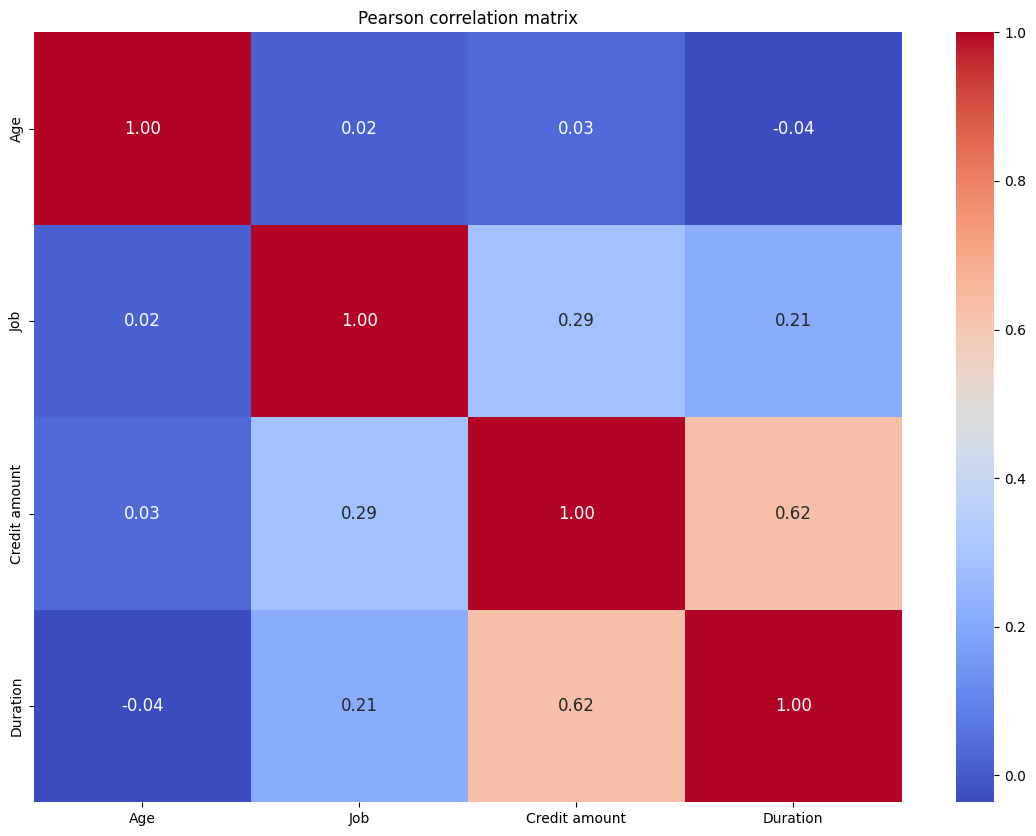

In [ ]:
plt.figure(figsize=(14,10))
sns.heatmap(num_variables.corr(numeric_only=True), cmap="coolwarm", annot=True, annot_kws={"size":12}, fmt='.2f')
plt.title('Pearson correlation matrix')
plt.show()

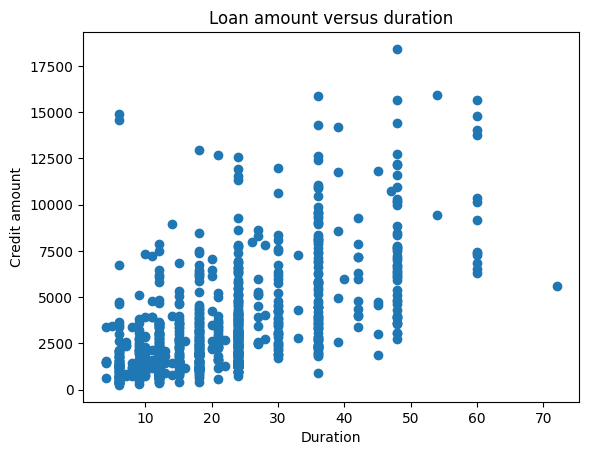

In [ ]:
x = df['Duration']
y = df['Credit amount']

plt.title("Loan amount versus duration")
plt.xlabel("Duration")
plt.ylabel("Credit amount")
plt.scatter(x, y)

plt.show()

In [ ]:
df = df.drop('Age group', axis = 1)
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,none,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,none,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## **Druga faza projekta**

In [ ]:
#One-hot encoding
#HOUSING, SAVING ACCOUNTS, CHECKING ACCOUNT, PURPOSE

df_encoded = pd.get_dummies(df,
                            columns=["Housing", "Saving accounts", "Checking account", "Purpose"],
                            drop_first=False)

# Pretvori samo one-hot stupce (koji su tipa bool) u int
bool_cols = df_encoded.select_dtypes(include='bool').columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

# Prikaz stupaca i prvih 10 redova
print(df_encoded.columns)
df_encoded.head(10)

Index(['Age', 'Sex', 'Job', 'Credit amount', 'Duration', 'Risk',
       'Housing_free', 'Housing_own', 'Housing_rent', 'Saving accounts_little',
       'Saving accounts_moderate', 'Saving accounts_none',
       'Saving accounts_quite rich', 'Saving accounts_rich',
       'Checking account_little', 'Checking account_moderate',
       'Checking account_none', 'Checking account_rich', 'Purpose_business',
       'Purpose_car', 'Purpose_domestic appliances', 'Purpose_education',
       'Purpose_furniture/equipment', 'Purpose_radio/TV', 'Purpose_repairs',
       'Purpose_vacation/others'],
      dtype='object')


,Age,Sex,Job,Credit amount,Duration,Risk,Housing_free,Housing_own,Housing_rent,Saving accounts_little,...,Checking account_none,Checking account_rich,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,67,male,2,1169,6,good,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
1,22,female,2,5951,48,bad,0,1,0,1,...,0,0,0,0,0,0,0,1,0,0
2,49,male,1,2096,12,good,0,1,0,1,...,1,0,0,0,0,1,0,0,0,0
3,45,male,2,7882,42,good,1,0,0,1,...,0,0,0,0,0,0,1,0,0,0
4,53,male,2,4870,24,bad,1,0,0,1,...,0,0,0,1,0,0,0,0,0,0
5,35,male,1,9055,36,good,1,0,0,0,...,1,0,0,0,0,1,0,0,0,0
6,53,male,2,2835,24,good,0,1,0,0,...,1,0,0,0,0,0,1,0,0,0
7,35,male,3,6948,36,good,0,0,1,1,...,0,0,0,1,0,0,0,0,0,0
8,61,male,1,3059,12,good,0,1,0,0,...,1,0,0,0,0,0,0,1,0,0
9,28,male,3,5234,30,bad,0,1,0,1,...,0,0,0,1,0,0,0,0,0,0


In [ ]:
df_encoded["Sex"] = df_encoded["Sex"].map({"male": 1, "female": 0})

df_encoded["Risk"] = df_encoded["Risk"].map({"good": 1, "bad": 0})

df_encoded.head(10)

,Age,Sex,Job,Credit amount,Duration,Risk,Housing_free,Housing_own,Housing_rent,Saving accounts_little,...,Checking account_none,Checking account_rich,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,67,1,2,1169,6,1,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
1,22,0,2,5951,48,0,0,1,0,1,...,0,0,0,0,0,0,0,1,0,0
2,49,1,1,2096,12,1,0,1,0,1,...,1,0,0,0,0,1,0,0,0,0
3,45,1,2,7882,42,1,1,0,0,1,...,0,0,0,0,0,0,1,0,0,0
4,53,1,2,4870,24,0,1,0,0,1,...,0,0,0,1,0,0,0,0,0,0
5,35,1,1,9055,36,1,1,0,0,0,...,1,0,0,0,0,1,0,0,0,0
6,53,1,2,2835,24,1,0,1,0,0,...,1,0,0,0,0,0,1,0,0,0
7,35,1,3,6948,36,1,0,0,1,1,...,0,0,0,1,0,0,0,0,0,0
8,61,1,1,3059,12,1,0,1,0,0,...,1,0,0,0,0,0,0,1,0,0
9,28,1,3,5234,30,0,0,1,0,1,...,0,0,0,1,0,0,0,0,0,0


In [ ]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 26 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Age                          1000 non-null   int64
 1   Sex                          1000 non-null   int64
 2   Job                          1000 non-null   int64
 3   Credit amount                1000 non-null   int64
 4   Duration                     1000 non-null   int64
 5   Risk                         1000 non-null   int64
 6   Housing_free                 1000 non-null   int64
 7   Housing_own                  1000 non-null   int64
 8   Housing_rent                 1000 non-null   int64
 9   Saving accounts_little       1000 non-null   int64
 10  Saving accounts_moderate     1000 non-null   int64
 11  Saving accounts_none         1000 non-null   int64
 12  Saving accounts_quite rich   1000 non-null   int64
 13  Saving accounts_rich         1000 non-null   int6

In [ ]:
from sklearn.preprocessing import MinMaxScaler

cols_to_scale = ['Age', 'Job', 'Credit amount', 'Duration']

scaler = MinMaxScaler()
df_encoded[cols_to_scale] = scaler.fit_transform(df_encoded[cols_to_scale])

df_encoded.head(10)

,Age,Sex,Job,Credit amount,Duration,Risk,Housing_free,Housing_own,Housing_rent,Saving accounts_little,...,Checking account_none,Checking account_rich,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,0.857143,1,0.666667,0.050567,0.029412,1,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
1,0.053571,0,0.666667,0.313690,0.647059,0,0,1,0,1,...,0,0,0,0,0,0,0,1,0,0
2,0.535714,1,0.333333,0.101574,0.117647,1,0,1,0,1,...,1,0,0,0,0,1,0,0,0,0
3,0.464286,1,0.666667,0.419941,0.558824,1,1,0,0,1,...,0,0,0,0,0,0,1,0,0,0
4,0.607143,1,0.666667,0.254209,0.294118,0,1,0,0,1,...,0,0,0,1,0,0,0,0,0,0
5,0.285714,1,0.333333,0.484483,0.470588,1,1,0,0,0,...,1,0,0,0,0,1,0,0,0,0
6,0.607143,1,0.666667,0.142236,0.294118,1,0,1,0,0,...,1,0,0,0,0,0,1,0,0,0
7,0.285714,1,1.000000,0.368548,0.470588,1,0,0,1,1,...,0,0,0,1,0,0,0,0,0,0
8,0.750000,1,0.333333,0.154561,0.117647,1,0,1,0,0,...,1,0,0,0,0,0,0,1,0,0
9,0.160714,1,1.000000,0.274238,0.382353,0,0,1,0,1,...,0,0,0,1,0,0,0,0,0,0


In [ ]:
df_encoded.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Age,1000.0,0.295464,0.203133,0.0,0.142857,0.250000,0.410714,1.0
Sex,1000.0,0.690000,0.462725,0.0,0.000000,1.000000,1.000000,1.0
Job,1000.0,0.634667,0.217871,0.0,0.666667,0.666667,0.666667,1.0
Credit amount,1000.0,0.166241,0.155317,0.0,0.061379,0.113871,0.204812,1.0
Duration,1000.0,0.248574,0.177336,0.0,0.117647,0.205882,0.294118,1.0
Risk,1000.0,0.700000,0.458487,0.0,0.000000,1.000000,1.000000,1.0
Housing_free,1000.0,0.108000,0.310536,0.0,0.000000,0.000000,0.000000,1.0
Housing_own,1000.0,0.713000,0.452588,0.0,0.000000,1.000000,1.000000,1.0
Housing_rent,1000.0,0.179000,0.383544,0.0,0.000000,0.000000,0.000000,1.0
Saving accounts_little,1000.0,0.603000,0.489521,0.0,0.000000,1.000000,1.000000,1.0


##Modeliranje podataka

Istraživanjem po internetu i temeljem znanstvenih radova, koje smo odabrali, zaključili smo da je za naš problem najbolje koristiti Random Forest algoritam.
Random Forest algoritam odličan je za manje skupove podataka, što je i naš slučaj, te analizom znanstvenih radova vidli smo da on ima najbolje rezultate testiranja, zajedno s neuralnom mrežom. No korištenje neuralne mreže dobro je rješenje za velike skupove podataka.

Za testiranje Random Forest modela koristit ćemo kombinaciju train/test podjele i križne validacije.

Podatke ćemo podijeliti tako da 80% služi za treniranje, a 20% za testiranje.

Nakon toga, tijekom optimizacije našeg modela, podijelit ćemo trening skup na 5 dijelova jer će u svakom krugu jean dio služiti za validaciju, a ostali za učenje.
Cilj nam je pronaći najbolje parametre na temelju F1-score-a.

In [ ]:
df_model = df_encoded

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

X = df_model.drop("Risk", axis=1)
y = df_model["Risk"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf_model = RandomForestClassifier(n_estimators=1000, random_state=42, class_weight={0: 2.33, 1: 1})
rf_model.fit(X_train, y_train)

#y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

thresholds = 0.8

y_pred = (y_proba > thresholds).astype(int)

print("MATRICA ZBUNJENOSTI:")
print(confusion_matrix(y_test, y_pred))

print("\nKLASIFIKACIJSKI IZVJEŠTAJ:")
print(classification_report(y_test, y_pred))

MATRICA ZBUNJENOSTI:
[[52  8]
 [75 65]]

KLASIFIKACIJSKI IZVJEŠTAJ:
              precision    recall  f1-score   support

           0       0.41      0.87      0.56        60
           1       0.89      0.46      0.61       140

    accuracy                           0.58       200
   macro avg       0.65      0.67      0.58       200
weighted avg       0.75      0.58      0.59       200



Random Forest Importance:
                        Feature  Importance
3                 Credit amount    0.198886
0                           Age    0.165026
4                      Duration    0.147867
15        Checking account_none    0.082964
2                           Job    0.050999
13      Checking account_little    0.041982
1                           Sex    0.029850
8        Saving accounts_little    0.028123
22             Purpose_radio/TV    0.026474
14    Checking account_moderate    0.025269
18                  Purpose_car    0.023590
10         Saving accounts_none    0.021535
21  Purpose_furniture/equipment    0.020457
6                   Housing_own    0.019977
17             Purpose_business    0.019679
7                  Housing_rent    0.014367
9      Saving accounts_moderate    0.013741
20            Purpose_education    0.013184
5                  Housing_free    0.012681
16        Checking account_rich    0.011323
11   Saving accounts_quite rich    0.009861
12    

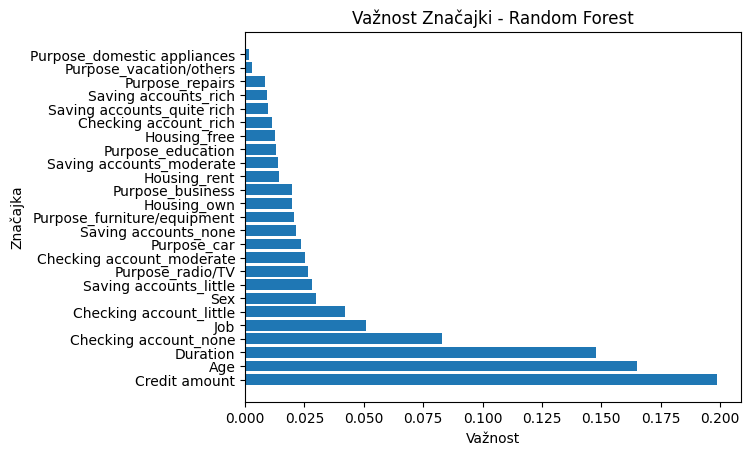

In [ ]:
importance_rf = rf_model.feature_importances_

importance_df_rf = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance_rf
}).sort_values(by='Importance', ascending=False)

print("Random Forest Importance:")
print(importance_df_rf)

plt.barh(importance_df_rf['Feature'], importance_df_rf['Importance'])
plt.title('Važnost Značajki - Random Forest')
plt.xlabel('Važnost')
plt.ylabel('Značajka')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

feature_names = X.columns.tolist()

class Individual:
    def __init__(self, num_features):
        self.features = [random.randint(0, 1) for _ in range(num_features)]

    def crossover(self, other):
        point = random.randint(1, len(self.features) - 1)
        child = Individual(len(self.features))
        child.features = self.features[:point] + other.features[point:]
        return child

    def mutate(self, mutation_rate=0.1):
        for i in range(len(self.features)):
            if random.random() < mutation_rate:
                self.features[i] = 1 - self.features[i]

class GeneticAlgorithm:
    def __init__(self, population_size, num_features, feature_names):
        self.population_size = population_size
        self.num_features = num_features
        self.feature_names = feature_names
        self.population = [Individual(num_features) for _ in range(population_size)]
        self.best_individual = None
        self.best_fitness = 0
        self.best_accuracy = 0

    def evaluate_individual(self, individual, X_train, y_train, X_test, y_test):
        selected = [i for i, bit in enumerate(individual.features) if bit == 1]
        if not selected:
            return 0.0, 0.0
        X_train_sel = X_train.iloc[:, selected]
        X_test_sel = X_test.iloc[:, selected]
        model = RandomForestClassifier(n_estimators=100, class_weight={0: 2.33, 1: 1}, random_state=42)
        model.fit(X_train_sel, y_train)
        preds = model.predict(X_test_sel)
        return f1_score(y_test, preds), accuracy_score(y_test, preds)

    def evolve(self, generations, X_train, y_train, X_test, y_test):
        for g in range(generations):
            fitness_scores = [self.evaluate_individual(ind, X_train, y_train, X_test, y_test) for ind in self.population]
            ranked_population = sorted(zip(self.population, fitness_scores), key=lambda x: x[1][0], reverse=True)

            if ranked_population[0][1][0] > self.best_fitness:
                self.best_individual = ranked_population[0][0]
                self.best_fitness = ranked_population[0][1][0]
                self.best_accuracy = ranked_population[0][1][1]

            best_individual = ranked_population[0][0]
            selected_features = [self.feature_names[i] for i, bit in enumerate(best_individual.features) if bit == 1]
            print(f'Generation {g+1}: Best Fitness (F1): {self.best_fitness:.4f}, Accuracy: {self.best_accuracy:.3f}')
            print(f'  Selected features: {selected_features}\n')

            new_population = [ranked_population[0][0]]
            while len(new_population) < self.population_size:
                parent1, parent2 = random.sample([x[0] for x in ranked_population[:5]], 2)
                child = parent1.crossover(parent2)
                child.mutate()
                new_population.append(child)
            self.population = new_population

    def print_best_individual(self):
        if self.best_individual:
            selected_features = [self.feature_names[i] for i, bit in enumerate(self.best_individual.features) if bit == 1]
            print("Best Individual (Selected Features):")
            print(f"  Features: {selected_features}")
            print(f"  F1-score: {self.best_fitness}")
            print(f"  Accuracy: {self.best_accuracy}")

In [ ]:
ga = GeneticAlgorithm(population_size=30, num_features=X.shape[1], feature_names=feature_names)

In [ ]:
ga.evolve(generations=8, X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)

Generation 1: Best Fitness (F1): 0.8667, Accuracy: 0.800
  Selected features: ['Age', 'Job', 'Credit amount', 'Duration', 'Housing_free', 'Housing_rent', 'Saving accounts_little', 'Saving accounts_moderate', 'Saving accounts_none', 'Saving accounts_rich', 'Checking account_little', 'Checking account_moderate', 'Checking account_none', 'Purpose_education', 'Purpose_repairs']

Generation 2: Best Fitness (F1): 0.8667, Accuracy: 0.800
  Selected features: ['Age', 'Job', 'Credit amount', 'Duration', 'Housing_free', 'Housing_rent', 'Saving accounts_little', 'Saving accounts_moderate', 'Saving accounts_none', 'Saving accounts_rich', 'Checking account_little', 'Checking account_moderate', 'Checking account_none', 'Purpose_education', 'Purpose_repairs']

Generation 3: Best Fitness (F1): 0.8667, Accuracy: 0.800
  Selected features: ['Age', 'Job', 'Credit amount', 'Duration', 'Housing_free', 'Housing_rent', 'Saving accounts_little', 'Saving accounts_moderate', 'Saving accounts_none', 'Saving acco

In [ ]:
ga.print_best_individual()

Best Individual (Selected Features):
  Features: ['Age', 'Sex', 'Job', 'Credit amount', 'Duration', 'Housing_free', 'Housing_rent', 'Saving accounts_little', 'Saving accounts_moderate', 'Saving accounts_none', 'Checking account_little', 'Checking account_moderate', 'Checking account_rich', 'Purpose_business', 'Purpose_car', 'Purpose_furniture/equipment', 'Purpose_radio/TV', 'Purpose_vacation/others']
  F1-score: 0.8686868686868687
  Accuracy: 0.805


In [ ]:
#značajke koje uzimamo: 'Age', 'Sex', 'Job', 'Credit amount', 'Duration', 'Housing_free', 'Housing_rent', 'Saving accounts_little', 'Saving accounts_moderate', 'Saving accounts_none', 'Checking account_little', 'Checking account_moderate', 'Checking account_rich', 'Purpose_business', 'Purpose_car', 'Purpose_furniture/equipment', 'Purpose_radio/TV', 'Purpose_vacation/others', 'Risk'

odabrane_znacajke = ['Age', 'Sex', 'Job', 'Credit amount', 'Duration', 'Housing_free', 'Housing_rent', 'Saving accounts_little', 'Saving accounts_moderate', 'Saving accounts_none', 'Checking account_little', 'Checking account_moderate', 'Checking account_rich', 'Purpose_business', 'Purpose_car', 'Purpose_furniture/equipment', 'Purpose_radio/TV', 'Purpose_vacation/others', 'Risk']

df_model2 = df_model[odabrane_znacajke].copy()

In [ ]:
X = df_model2.drop("Risk", axis=1)
y = df_model2["Risk"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf_model = RandomForestClassifier(n_estimators=1000, random_state=42, class_weight={0: 2.33, 1: 1})
rf_model.fit(X_train, y_train)

#y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

thresholds = 0.8
y_pred = (y_proba > thresholds).astype(int)

print("MATRICA ZBUNJENOSTI:")
print(confusion_matrix(y_test, y_pred))

print("\nKLASIFIKACIJSKI IZVJEŠTAJ:")
print(classification_report(y_test, y_pred))

MATRICA ZBUNJENOSTI:
[[49 11]
 [69 71]]

KLASIFIKACIJSKI IZVJEŠTAJ:
              precision    recall  f1-score   support

           0       0.42      0.82      0.55        60
           1       0.87      0.51      0.64       140

    accuracy                           0.60       200
   macro avg       0.64      0.66      0.60       200
weighted avg       0.73      0.60      0.61       200



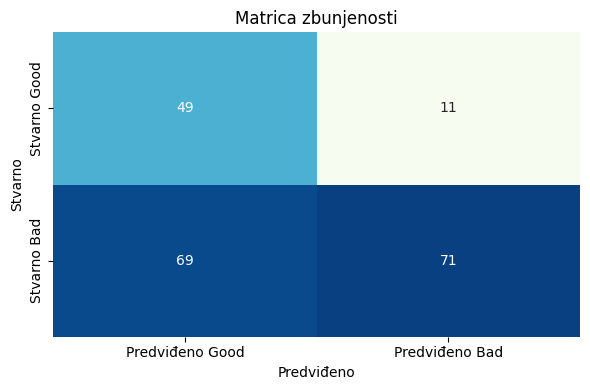

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='GnBu', cbar=False,
            xticklabels=['Predviđeno Good', 'Predviđeno Bad'],
            yticklabels=['Stvarno Good', 'Stvarno Bad'])
plt.xlabel('Predviđeno')
plt.ylabel('Stvarno')
plt.title('Matrica zbunjenosti')
plt.tight_layout()
plt.show()

Random Forest Importance:
                        Feature  Importance
3                 Credit amount    0.223404
0                           Age    0.183132
4                      Duration    0.160296
10      Checking account_little    0.069987
2                           Job    0.054284
11    Checking account_moderate    0.045827
7        Saving accounts_little    0.035020
1                           Sex    0.030713
16             Purpose_radio/TV    0.029938
14                  Purpose_car    0.026566
6                  Housing_rent    0.023151
9          Saving accounts_none    0.023097
15  Purpose_furniture/equipment    0.021392
5                  Housing_free    0.020276
13             Purpose_business    0.019070
8      Saving accounts_moderate    0.015338
12        Checking account_rich    0.015091
17      Purpose_vacation/others    0.003418


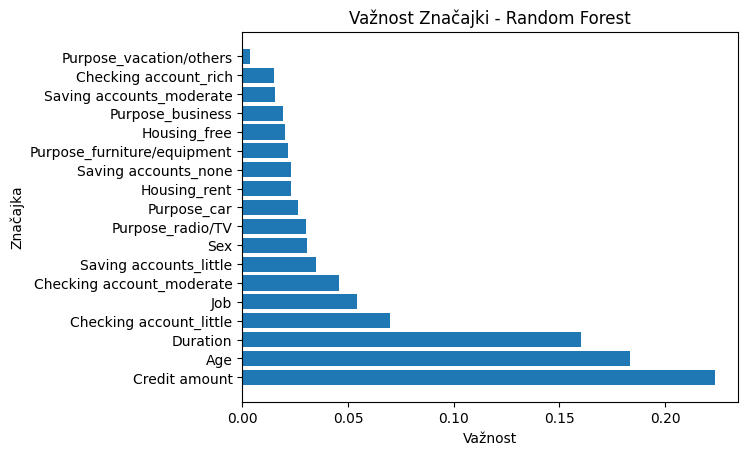

In [ ]:
importance_rf = rf_model.feature_importances_

importance_df_rf = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance_rf
}).sort_values(by='Importance', ascending=False)

print("Random Forest Importance:")
print(importance_df_rf)

plt.barh(importance_df_rf['Feature'], importance_df_rf['Importance'])
plt.title('Važnost Značajki - Random Forest')
plt.xlabel('Važnost')
plt.ylabel('Značajka')
plt.show()

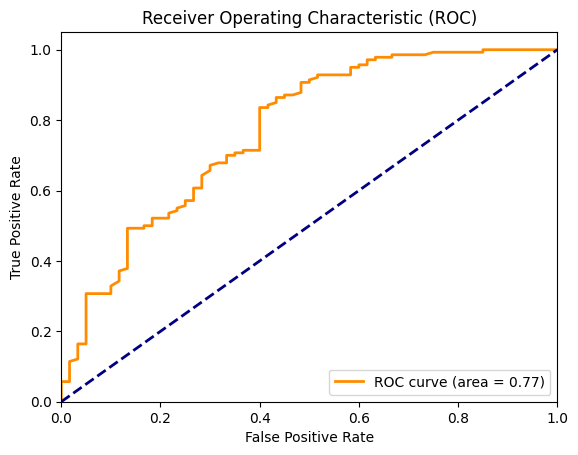

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()


## Korištenje

In [ ]:
good_client = pd.DataFrame([{
    'Age': 45,
    'Sex': 0,
    'Job': 3,
    'Credit amount': 2000,
    'Duration': 12,
    'Housing_free': 0,
    'Housing_own': 1,
    'Housing_rent': 0,
    'Saving accounts_little': 0,
    'Saving accounts_moderate': 1,
    'Saving accounts_none': 0,
    'Saving accounts_quite rich': 0,
    'Saving accounts_rich': 0,
    'Checking account_little': 0,
    'Checking account_moderate': 1,
    'Checking account_none': 0,
    'Checking account_rich': 0,
    'Purpose_business': 0,
    'Purpose_car': 0,
    'Purpose_domestic appliances': 0,
    'Purpose_education': 0,
    'Purpose_furniture/equipment': 0,
    'Purpose_radio/TV': 0,
    'Purpose_repairs': 0,
    'Purpose_vacation/others': 1
}], columns=X_train.columns)

bad_client = pd.DataFrame([{
    'Age': 19,
    'Sex': 1,
    'Job': 2,
    'Credit amount': 150000,
    'Duration': 60,
    'Housing_free': 1,
    'Housing_own': 0,
    'Housing_rent': 0,
    'Saving accounts_little': 0,
    'Saving accounts_moderate': 0,
    'Saving accounts_none': 1,
    'Saving accounts_quite rich': 0,
    'Saving accounts_rich': 0,
    'Checking account_little': 0,
    'Checking account_moderate': 0,
    'Checking account_none': 1,
    'Checking account_rich': 0,
    'Purpose_business': 0,
    'Purpose_car': 1,
    'Purpose_domestic appliances': 0,
    'Purpose_education': 0,
    'Purpose_furniture/equipment': 0,
    'Purpose_radio/TV': 0,
    'Purpose_repairs': 0,
    'Purpose_vacation/others': 0
}], columns=X_train.columns)

prediction = rf_model.predict(good_client)

risk_category = 'bad' if prediction[0] == 1 else 'good'
print("Ovaj klijent spada u:", risk_category, "risk grupu.")

Ovaj klijent spada u: good risk grupu.


In [ ]:
prediction = rf_model.predict(bad_client)

risk_category = 'bad' if prediction[0] == 1 else 'good'
print("Ovaj klijent spada u:", risk_category, "risk grupu.")

Ovaj klijent spada u: bad risk grupu.
